# 13장 · 순차 워크플로의 입력·출력 연결

순차 워크플로에서는 앞 단계의 반환값이 다음 호출의 입력이 됩니다. 중간값이 비면 이후 단계가 어떤 자료를 잃는지 살펴봅니다.

영수증 문의를 요약한 뒤 비용 문의인지 분류하고 안내 문장을 씁니다. 최종 문장만 보면 세 번의 호출 사이에서 무슨 정보가 넘어갔는지 알기 어렵습니다. 각 단계의 출력 한 건을 다음 단계의 입력으로 직접 이어 보세요.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 요약 출력을 분류 입력으로 전달

각 단계는 받은 자료와 지시를 이용해 새 문자열을 반환합니다. 이번 실습의 mock_call은 정해 둔 답을 주는 대역입니다. 최종 글의 품질보다 단계 사이에 실제로 건넨 값을 확인합니다.

<!-- lesson-visual visual-summary -->
**요약의 반환값은 다음 호출의 입력입니다**

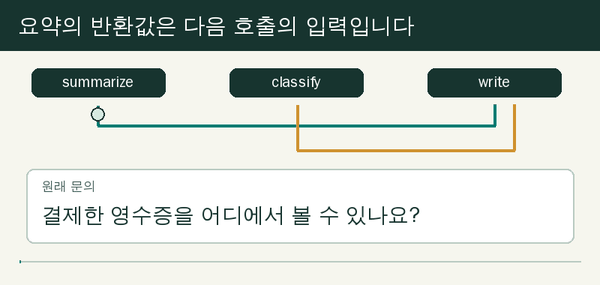

첫 호출이 돌려준 문장 전체가 분류 함수로 이동합니다. 분류 결과 billing은 요약과 함께 작성 단계에 전달됩니다. 이 예제는 단계별 응답을 고정한 모의 호출입니다.
<!-- /lesson-visual visual-summary -->


### 요약 단계의 정보 손실

<p>순차 흐름의 뒤 단계는 앞 단계가 넘긴 정보에 의존합니다. 원문에 “영수증을 찾을 수 없고 로그인 오류도 난다”는 내용이 있는데 요약이 영수증만 남기면 분류와 안내도 한쪽으로 치우칠 수 있습니다.</p>

<p>요약 길이를 늘리는 방법과 원문을 뒤 단계에도 전달하는 방법은 서로 다른 설계입니다. 어떤 정보를 남겨야 하는지 먼저 정하고, 입력 크기와 확인 부담을 함께 비교하세요.</p>


### 셀 01 · mock_call()의 요약 반환값

첫 번째 요청의 질문은 그대로 두고, 반환된 요약을 변수에 보관하세요.


In [1]:
def mock_call(name, instruction, data):
    outputs = {"summarize": "사용자가 결제 영수증 확인 방법을 문의했다.",
               "classify": "billing", "write": "결제 영수증 확인 문의를 접수했습니다. 실제 계정 확인은 담당자에게 요청하세요."}
    return outputs[name]

request = "결제한 영수증을 어디에서 볼 수 있나요?"
summary = mock_call("summarize", "문의를 한 문장으로 요약하세요.", request)
print(summary)

사용자가 결제 영수증 확인 방법을 문의했다.


영수증 확인 방법을 묻는 문장이 나옵니다. 모의 함수는 단계 이름으로 준비된 답을 골라 주므로 입력을 바꿔도 요약 품질을 시험할 수는 없습니다.


### 순차 호출의 단계 분할

<p>여러 작업을 한 번에 요청하면 어디에서 잘못되었는지 구분하기 어려울 수 있습니다. 요약·분류·문장 작성을 따로 실행하면 중간 결과를 볼 수 있지만 호출 수와 대기 시간도 늘어납니다. 작업을 나눈다는 사실만으로 품질이 좋아진다고 단정하지 않습니다.</p>

<p>이번 흐름에서는 Python 코드가 항상 요약, 분류, 작성 순서를 정합니다. 모델이 다음 함수를 선택하는 에이전트가 아닙니다. 모델은 각 단계에서 입력을 받아 텍스트를 돌려줄 뿐입니다.</p>

<table><caption>세 단계의 입출력</caption><thead><tr><th scope="col">단계</th><th scope="col">입력</th><th scope="col">출력</th></tr>
</thead><tbody><tr><td>summarize</td><td>원본 문의</td><td>요약 한 문장</td></tr>
<tr><td>classify</td><td>요약</td><td>billing/technical/clarify</td></tr>
<tr><td>write</td><td>요약과 분야를 담은 JSON 문자열</td><td>접수 안내</td></tr>
</tbody></table>


### 셀 02 · 분류 호출에 요약 전달

방금 얻은 summary를 세 번째 인자로 넣습니다.


In [2]:
category = mock_call("classify", "billing, technical, clarify 중 하나를 쓰세요.", summary)
print(category)

billing


billing이 나옵니다. 다음 단계에 이 단어만 보내면 무엇 때문에 결제 문의로 분류했는지 알 수 없습니다.


### 고정 응답으로 함수 연결 시험하기

<p>mock_call은 단계 이름으로 미리 저장한 값을 찾아 반환합니다. 입력 문장을 바꾸어도 같은 문자열을 돌려주므로 분류 정확도는 측정할 수 없습니다. 여기서는 요약 반환값이 실제로 다음 호출의 입력에 들어갔는지 로그로 확인합니다.</p>


## JSON으로 다중 입력 조립

요약은 무엇을 물었는지, 분류는 어느 분야인지 알려 줍니다. 하나의 문자열로 넘겨야 해도 칸 이름을 남겨 두면 모델과 사람이 같은 구조를 읽을 수 있습니다.


### 과제 03 · JSON으로 분류·요약 묶기

summary와 category를 같은 이름의 두 칸에 넣고 JSON으로 표시하세요. 한글은 읽을 수 있게 남깁니다.


In [3]:
import json
# 두 값을 JSON으로 묶으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>import json
writing_input = json.dumps({&quot;summary&quot;: summary, &quot;category&quot;: category}, ensure_ascii=False)
print(writing_input)</code></pre>
<p>실행 결과</p><pre><code>{&quot;summary&quot;: &quot;사용자가 결제 영수증 확인 방법을 문의했다.&quot;, &quot;category&quot;: &quot;billing&quot;}</code></pre>
<p>summary와 category가 구분되어 보입니다. 요약문에 들어 있는 영수증과 코드가 받은 분류값 billing을 한 번에 확인할 수 있습니다.</p>
</details>


### 작성 함수로 함께 전달되는 두 값

<p>분류 함수에는 앞서 만든 summary 하나가 들어갑니다. 작성 함수에는 summary와 category가 모두 필요해 두 값을 JSON 문자열로 묶습니다. 로그의 classify 입력과 write 입력에서 이 차이를 찾아보세요.</p>


### 셀 04 · 빈 문자열의 ValueError 처리

분류 전에 요약이 공백만 돌아온 상황입니다. 뒤의 호출에 보낼 값이 있는지 먼저 봅니다.


In [4]:
def checked_text(stage, output):
    if not isinstance(output, str) or not output.strip():
        raise ValueError("빈 단계 출력: " + stage)
    return output.strip()

try:
    checked_text("summarize", "   ")
except ValueError as error:
    print(error)

빈 단계 출력: summarize


오류 메시지에 summarize가 보입니다. 뒤에서 분류 실패가 난 것으로 오해하지 않고 처음 비어 버린 위치로 돌아갈 수 있습니다.


### 빈 중간값의 실패 처리

<p>분류 단계가 빈 문자열을 반환했는데 작성 단계로 계속 진행하면 정상처럼 보이는 안내문을 만들 수 있습니다. 빈 출력과 허용하지 않은 분류를 즉시 거부하고 뒤 단계를 실행하지 않도록 합니다.</p>

<p>이 예제는 오류를 예외로 알립니다. 실패 시 앞 단계 로그를 외부에 반환하는 구조까지 구현하지 않았습니다. 실제 운영 로그를 만들 때는 성공 단계와 실패 단계를 함께 보관하되 민감한 입력 전체를 무조건 저장하지 않습니다.</p>

<table><caption>실패 조건</caption><thead><tr><th scope="col">발견 위치</th><th scope="col">처리</th></tr>
</thead><tbody><tr><td>시작 전 빈 문의</td><td>ValueError, 호출 없음</td></tr>
<tr><td>단계의 빈 출력</td><td>해당 단계에서 예외, 이후 중단</td></tr>
<tr><td>허용값 밖 분류</td><td>작성 단계 실행 전 중단</td></tr>
<tr><td>SDK 응답 미완료</td><td>호출 함수에서 예외</td></tr>
<tr><td>내용은 틀리지만 형식 정상</td><td>원문 대조로 별도 발견</td></tr>
</tbody></table>


## 단계별 호출 로그와 중간값 검증

다음 제공 함수는 각 단계의 입력, 출력, 시간을 log에 남깁니다. 앞 단계가 성공해야 다음 요청을 보냅니다. 실제 SDK를 쓸 때는 같은 자리에 responses.create로 본문을 읽는 함수를 연결할 수 있습니다.

<!-- lesson-visual detail-trace -->
**요약이 공백이면 다음 호출은 몇 번 실행될까요?**

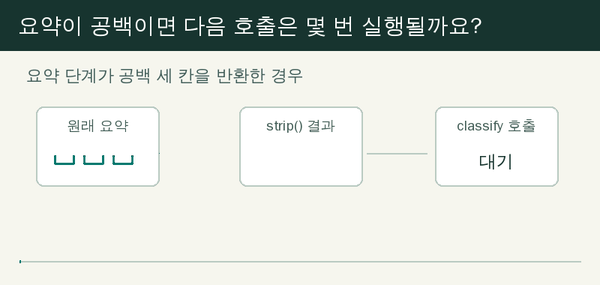

summarize가 공백만 돌려주는 경우를 run_workflow의 검사 순서로 따라갑니다. strip() 결과가 빈 문자열이면 해당 단계 이름으로 예외가 발생해 분류와 안내 작성은 시작하지 않습니다.
<!-- /lesson-visual detail-trace -->


### 셀 05 · 호출 로그의 단계별 input

처음에 입력한 질문과 두 번째 호출에 실제로 건넨 문자열을 구분하세요.

두 번째 호출이 받은 것은 첫 단계의 요약 ‘사용자가 결제 영수증 확인 방법을 문의했다.’입니다. 분류 결과 billing은 그다음 작성 단계에서 요약과 함께 쓰입니다. result["log"][1]["input"]에서 분류 전의 요약을 확인하세요.


In [5]:
import json
from time import perf_counter
PROMPTS = {"summarize": "요약하세요.", "classify": "분류하세요.", "write": "안내를 작성하세요."}

def run_workflow(call, request):
    if not request.strip():
        raise ValueError("빈 문의")
    log = []
    def step(name, data):
        started = perf_counter()
        output = call(name, PROMPTS[name], data)
        if not isinstance(output, str) or not output.strip():
            raise ValueError("빈 단계 출력: " + name)
        log.append({"stage": name, "input": data, "output": output,
                    "seconds": round(perf_counter() - started, 3)})
        return output.strip()
    summary = step("summarize", request)
    category = step("classify", summary)
    if category not in {"billing", "technical", "clarify"}:
        raise ValueError("허용하지 않은 분류")
    writing_input = json.dumps({"summary": summary, "category": category}, ensure_ascii=False)
    answer = step("write", writing_input)
    return {"summary": summary, "category": category, "answer": answer, "log": log}

result = run_workflow(mock_call, request)
print(result["log"][1]["input"])

사용자가 결제 영수증 확인 방법을 문의했다.


두 번째 호출 기록의 input은 첫 호출이 만든 요약입니다. result의 answer는 세 번째 모의 호출이 돌려준 접수 안내입니다. 계정 조회나 환불을 실행한 기록은 없습니다.


### 단계 실행 함수

<p>step은 단계 이름과 입력을 받아 호출하고 결과를 검사합니다. 입력과 출력, 시간을 log에 함께 남기므로 어느 단계에서 문제가 생겼는지 읽을 수 있습니다. 이번 실습은 가상 문의만 로그에 남깁니다. 실제 서비스에서는 개인정보가 로그에 남지 않도록 범위와 보관 규칙을 정해야 합니다.</p>

<p>run_workflow의 call 인자는 모델 호출을 담당하는 함수입니다. 기본 실행은 mock_call을 전달합니다. 이처럼 호출 경계를 분리하면 인터넷 없이도 연결 순서와 실패 경로를 검사할 수 있습니다.</p>


## 돌아보기

분류가 허용 목록에 없는 payment라면 어느 단계에서 중단해야 할까요? 작성 입력을 만들기 전에 category를 검사한 위치를 찾아 보세요. 세 번의 호출이 항상 같은 순서인 이 방식에서 다음 장은 분류별로 다른 경로를 고릅니다.

### 세 단계의 연결

**문의 요약**　원본의 문제와 요청을 남깁니다.

```
summary = "사용자가 결제 영수증 확인 방법을 문의했다."
```

**분야 분류**　요약을 허용된 분야 하나로 분류합니다.

```
category = "billing"
```

**접수 안내**　요약과 분야를 함께 전달합니다.

```
summary: 결제 영수증 확인 문의
category: billing
```
